# Radar Lab Notebook

This notebook demonstrates a more realistic pulsed-radar model with a dedicated transmitter, minimum detectable signal, Swerling ranges, and Doppler behavior.

## Sensitivity, range, and Doppler example

This example models a 10 GHz pulsed radar with a 1 m² target and a receiver sensitivity estimate. It includes charts for waveform timing, range behavior, and Doppler shift.

In [3]:
import sys
from pathlib import Path

repo_root = Path.cwd()
for candidate in (repo_root, *repo_root.parents):
    if (candidate / 'radar_model.py').exists():
        sys.path.insert(0, str(candidate))
        break

import numpy as np
import matplotlib.pyplot as plt
from radar_model import RadarTransmitterModel, RadarReceiverModel, RadarTargetModel, PulsedRadarModel, AntennaModel, SignalModel, C0

radar = PulsedRadarModel(
    transmitter=RadarTransmitterModel(
        antenna=AntennaModel(
            gain_db=30.0,
            carrier_frequency_hz=10e9,
            transmit_power_w=10000.0,
            effective_aperture_m2=0.6,
        ),
        pulse_train=SignalModel(
            carrier_frequency_hz=10e9,
            pulse_width_s=2e-6,
            peak_power_w=10000.0,
            amplitude_v=1.0,
            duty_cycle=0.2,
            pulse_count=4,
            sampling_interval_s=1e-10,
        ),
    ),
    receiver=RadarReceiverModel(
        noise_figure_db=4.0,
        bandwidth_hz=1e6,
        detection_snr_db=13.0,
    ),
    target=RadarTargetModel(
        rcs_m2=1.0,
        radial_velocity_m_s=30.0,
        swerling_case=1,
    ),
)

print(f"Range resolution: {radar.range_resolution_m:.2f} m")
print(f"MDS: {10*np.log10(radar.minimum_detectable_signal_w * 1000):.2f} dBm")
print(f"Target Doppler at 30 m/s: {radar.target_doppler_hz / 1e3:.2f} kHz")

Range resolution: 299.79 m
MDS: -96.98 dBm
Target Doppler at 30 m/s: 2.00 kHz


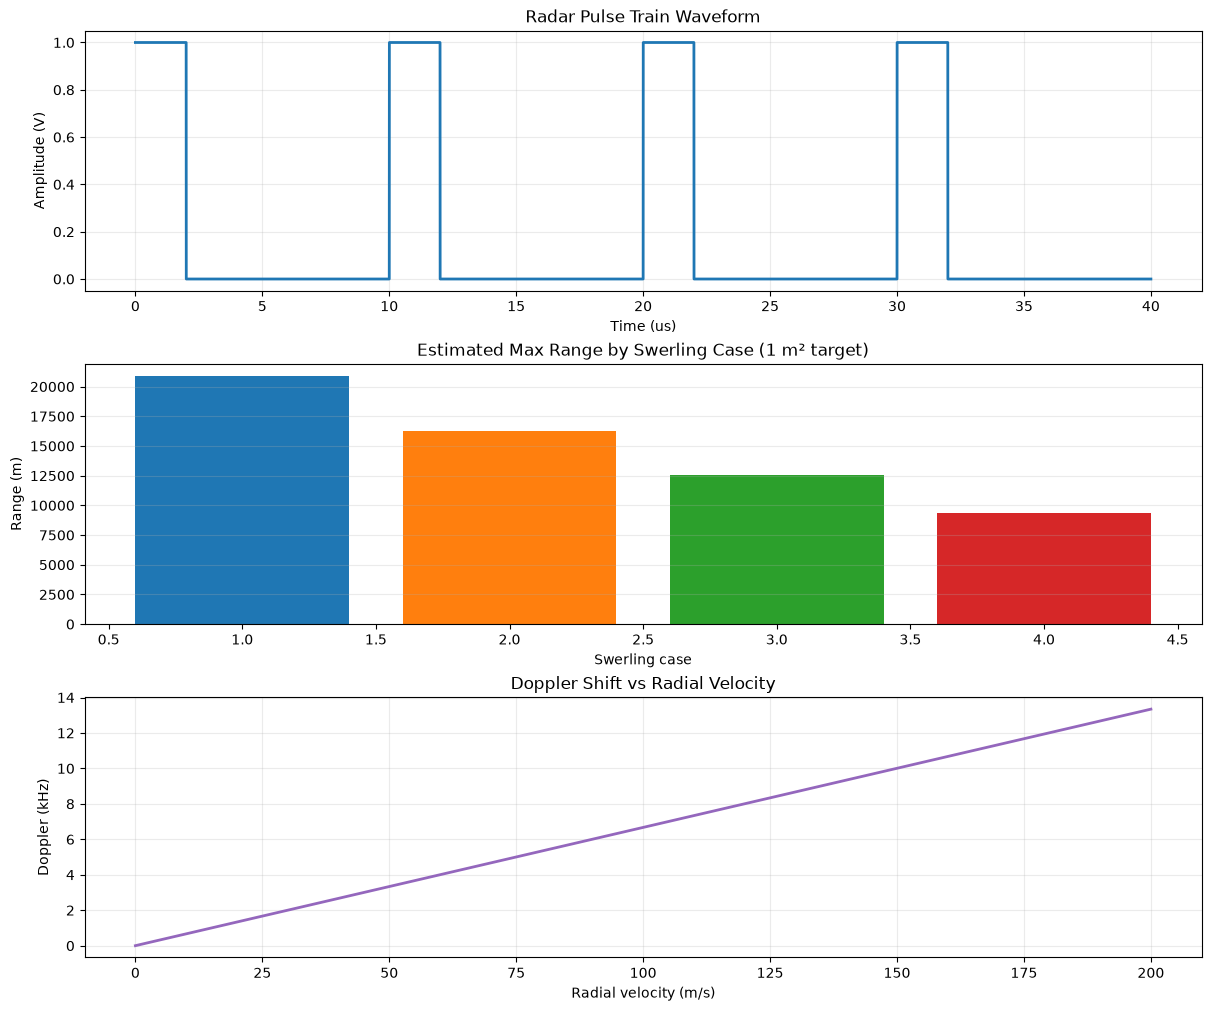

Swerling ranges: {1: 20859.91624930459, 2: 16270.734674457583, 3: 12515.949749582755, 4: 9386.962312187066}
Maximum range for 1 m² target: 20859.92 m


In [4]:
# Build plots for waveform, Swerling range, and Doppler

time_s = radar.pulse_train.time_axis_s
waveform_v = radar.pulse_train.waveform_v

swerling_ranges = radar.swerling_ranges_m(target_rcs_m2=1.0)
velocities_m_s = np.linspace(0.0, 200.0, 200)
doppler_hz = 2.0 * velocities_m_s * radar.transmitter.pulse_train.carrier_frequency_hz / C0

fig, axes = plt.subplots(3, 1, figsize=(12, 10), constrained_layout=True)

axes[0].plot(time_s * 1e6, waveform_v, color='tab:blue', linewidth=2)
axes[0].set_title('Radar Pulse Train Waveform')
axes[0].set_xlabel('Time (us)')
axes[0].set_ylabel('Amplitude (V)')
axes[0].grid(alpha=0.25)

axes[1].bar(list(swerling_ranges.keys()), list(swerling_ranges.values()), color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])
axes[1].set_title('Estimated Max Range by Swerling Case (1 m² target)')
axes[1].set_xlabel('Swerling case')
axes[1].set_ylabel('Range (m)')
axes[1].grid(alpha=0.25, axis='y')

axes[2].plot(velocities_m_s, doppler_hz / 1e3, color='tab:purple', linewidth=2)
axes[2].set_title('Doppler Shift vs Radial Velocity')
axes[2].set_xlabel('Radial velocity (m/s)')
axes[2].set_ylabel('Doppler (kHz)')
axes[2].grid(alpha=0.25)

plt.show()

print(f"Swerling ranges: {swerling_ranges}")
print(f"Maximum range for 1 m² target: {radar.max_range_m(target_rcs_m2=1.0):.2f} m")